In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ngosa\Desktop\GITHUB ROADMAP\hotel_bookings demand.csv")
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.columns


Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [4]:
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:
df.shape


(119390, 32)

In [6]:
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)


In [7]:
df[['arrival_date']].head()


,arrival_date
0,2015-07-01
1,2015-07-01
2,2015-07-01
3,2015-07-01
4,2015-07-01


In [8]:
daily_demand = df.groupby('arrival_date').size()
daily_demand.head()


arrival_date
2015-07-01    122
2015-07-02     93
2015-07-03     56
2015-07-04     88
2015-07-05     53
dtype: int64

In [9]:
daily_adr = df.groupby('arrival_date')['adr'].mean()
daily_adr.head()


arrival_date
2015-07-01     92.828934
2015-07-02     82.205484
2015-07-03     97.183036
2015-07-04     85.582273
2015-07-05    100.002642
Name: adr, dtype: float64

In [10]:
daily_cancellations = df.groupby('arrival_date')['is_canceled'].sum()
daily_cancellations.head()


arrival_date
2015-07-01    19
2015-07-02    57
2015-07-03    19
2015-07-04    43
2015-07-05    16
Name: is_canceled, dtype: int64

In [11]:
ts = pd.DataFrame({
    'demand': daily_demand,
    'adr': daily_adr,
    'cancellations': daily_cancellations
})
ts.head()


,demand,adr,cancellations
arrival_date,,,
2015-07-01,122,92.828934,19
2015-07-02,93,82.205484,57
2015-07-03,56,97.183036,19
2015-07-04,88,85.582273,43
2015-07-05,53,100.002642,16


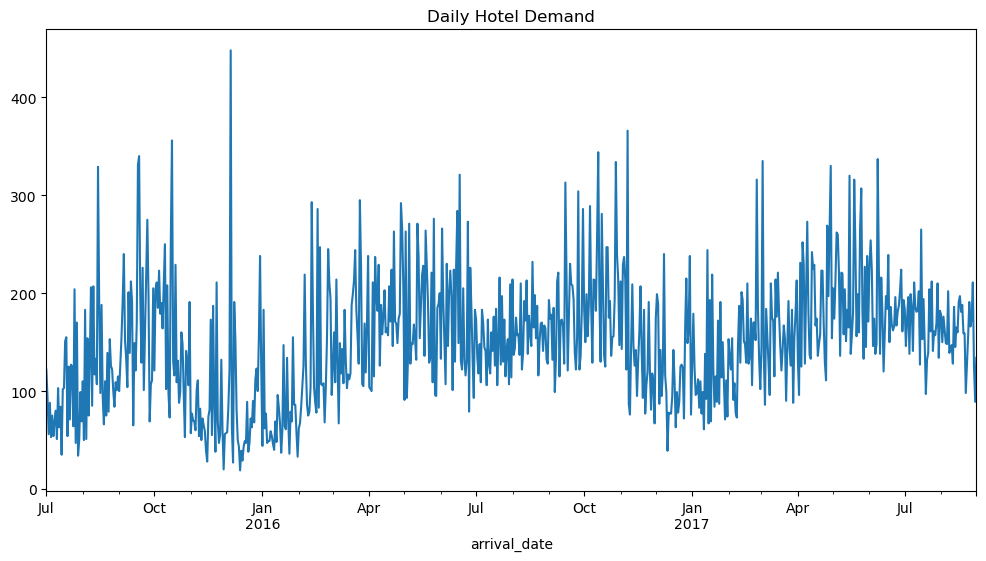

In [12]:
ts['demand'].plot(figsize=(12,6))
plt.title("Daily Hotel Demand")
plt.show()


In [13]:
!pip install prophet


In [14]:
import pandas as pd

# Create arrival_date column
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)

# Create daily demand (number of bookings per day)
daily_demand = df.groupby('arrival_date').size().reset_index(name='demand')

# Prepare for Prophet
prophet_df = daily_demand.rename(columns={'arrival_date': 'ds', 'demand': 'y'})
prophet_df.head()


,ds,y
0,2015-07-01,122
1,2015-07-02,93
2,2015-07-03,56
3,2015-07-04,88
4,2015-07-05,53


In [17]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(prophet_df)




20:27:38 - cmdstanpy - INFO - Chain [1] start processing
20:27:38 - cmdstanpy - INFO - Chain [1] done processing


In [18]:
future = model.make_future_dataframe(periods=90)
future.tail()


,ds
878,2017-11-25
879,2017-11-26
880,2017-11-27
881,2017-11-28
882,2017-11-29


In [19]:
forecast = model.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()


,ds,yhat,yhat_lower,yhat_upper
878,2017-11-25,149.391035,82.718638,212.533099
879,2017-11-26,114.552920,53.296380,179.173787
880,2017-11-27,149.835558,89.795613,219.060834
881,2017-11-28,112.386244,48.765620,166.006326
882,2017-11-29,129.675994,63.986918,188.492243


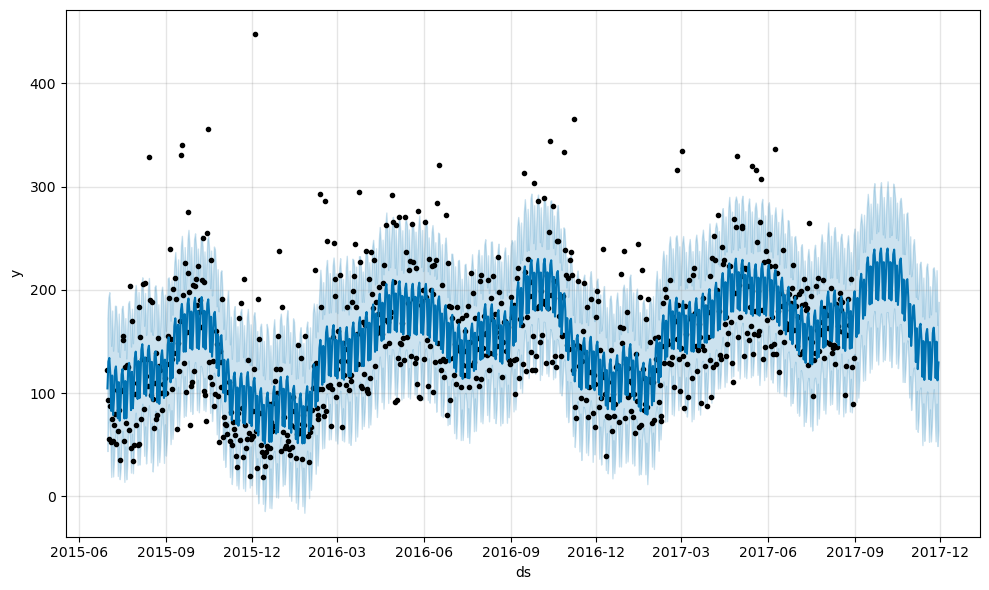

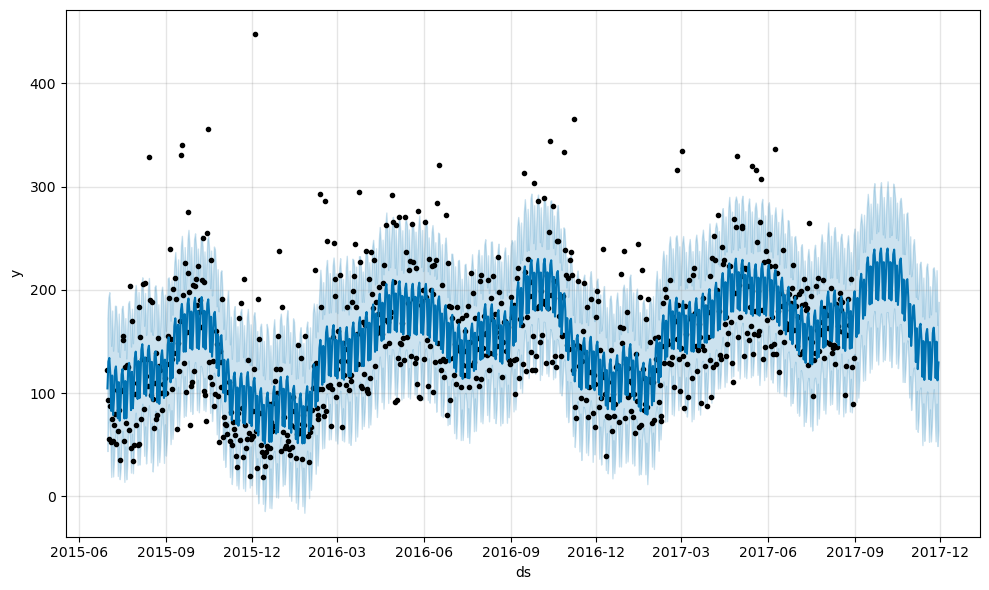

In [20]:
model.plot(forecast)


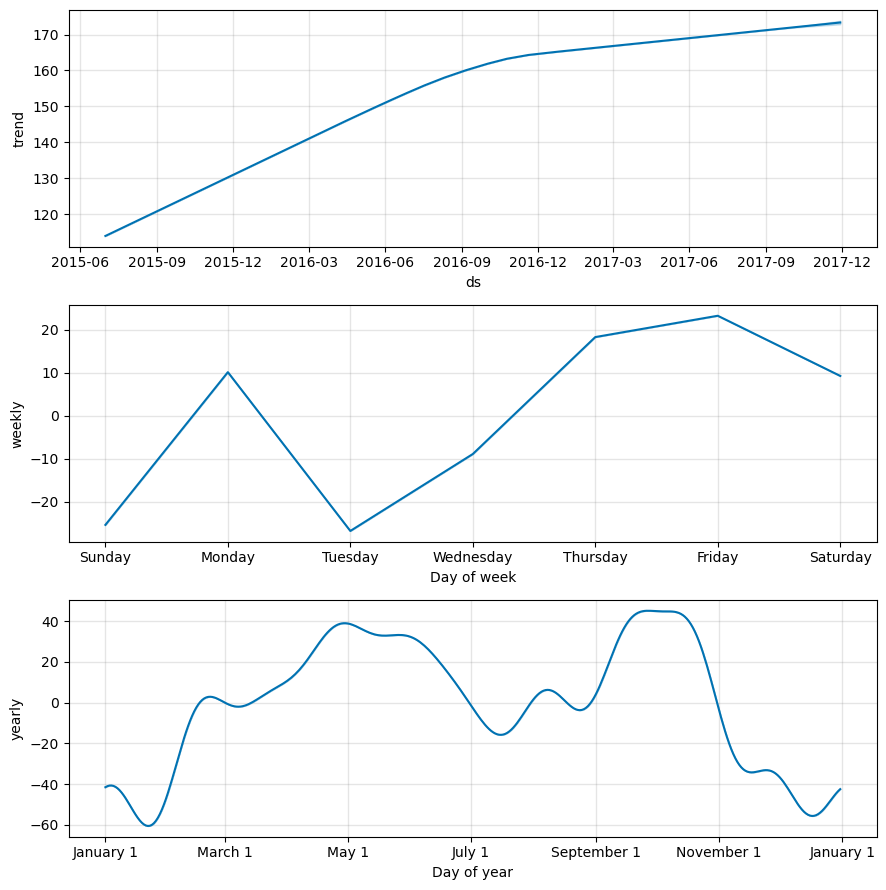

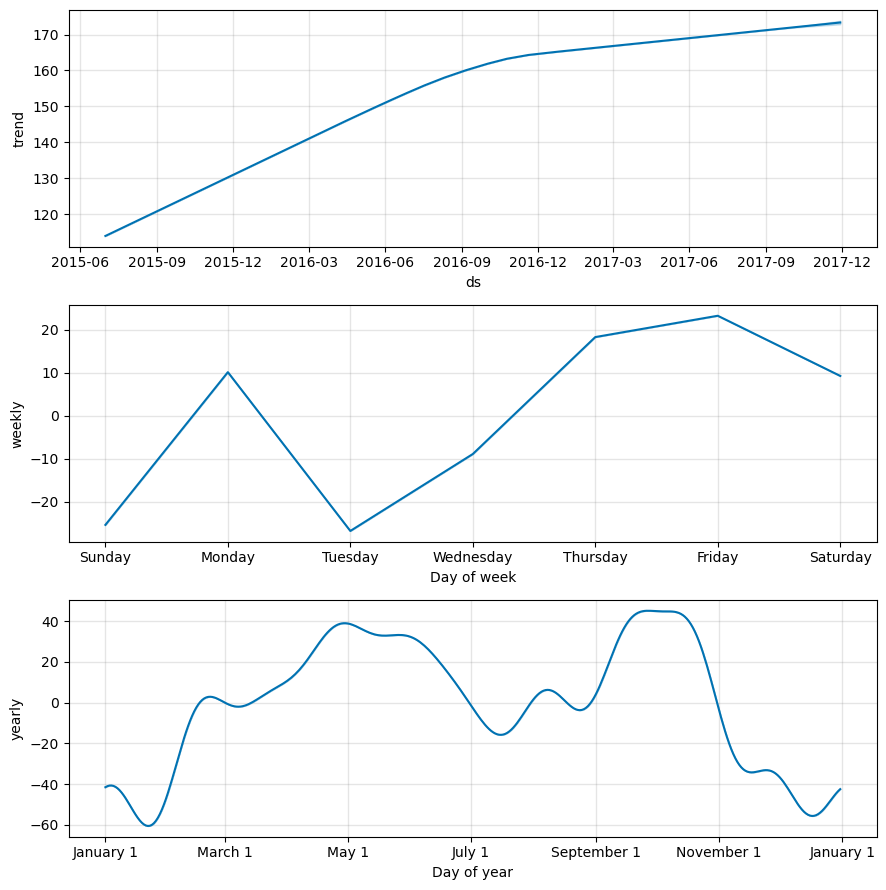

In [21]:
model.plot_components(forecast)


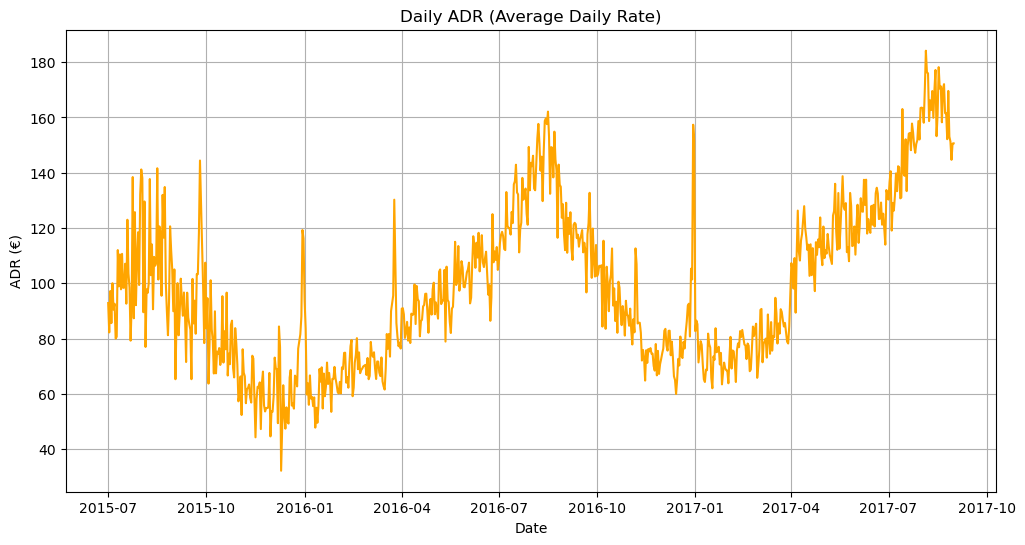

In [34]:
daily_adr = df.groupby('arrival_date')['adr'].mean()

plt.figure(figsize=(12,6))
plt.plot(daily_adr.index, daily_adr.values, color='orange')
plt.title("Daily ADR (Average Daily Rate)")
plt.xlabel("Date")
plt.ylabel("ADR (€)")
plt.grid(True)
plt.show()



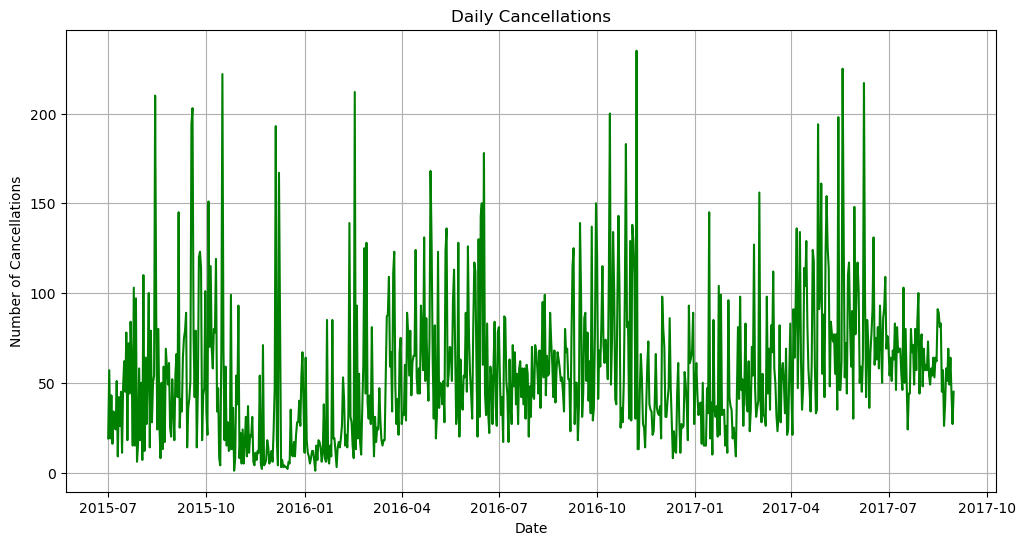

In [35]:
daily_cancellations_series = daily_cancellations.set_index('arrival_date')['is_canceled']

plt.figure(figsize=(12,6))
plt.plot(daily_cancellations_series.index, daily_cancellations_series.values, color='green')
plt.title("Daily Cancellations")
plt.xlabel("Date")
plt.ylabel("Number of Cancellations")
plt.grid(True)
plt.show()



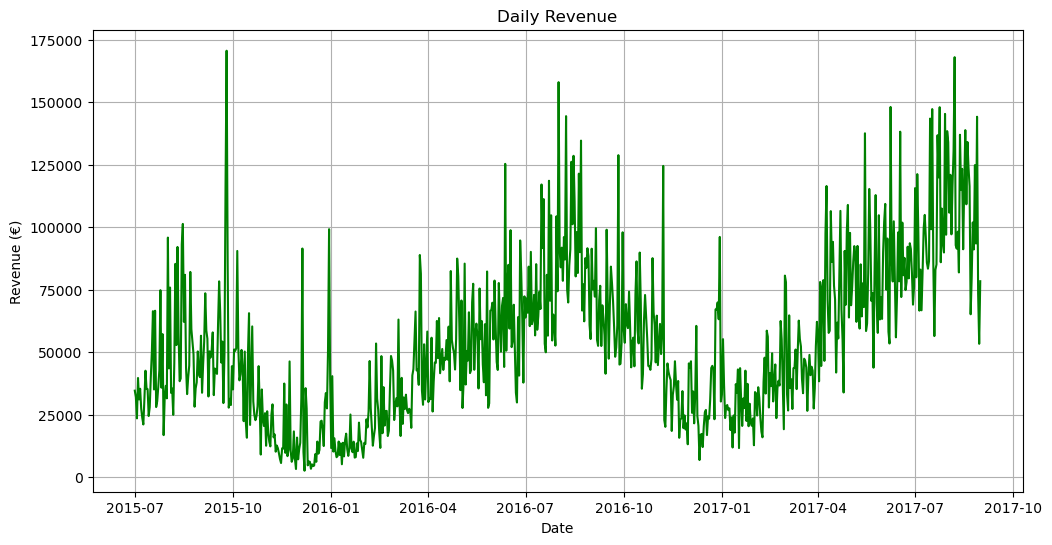

In [36]:
daily_revenue = df.groupby('arrival_date')['revenue'].sum()

plt.figure(figsize=(12,6))
plt.plot(daily_revenue.index, daily_revenue.values, color='green')
plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (€)")
plt.grid(True)
plt.show()



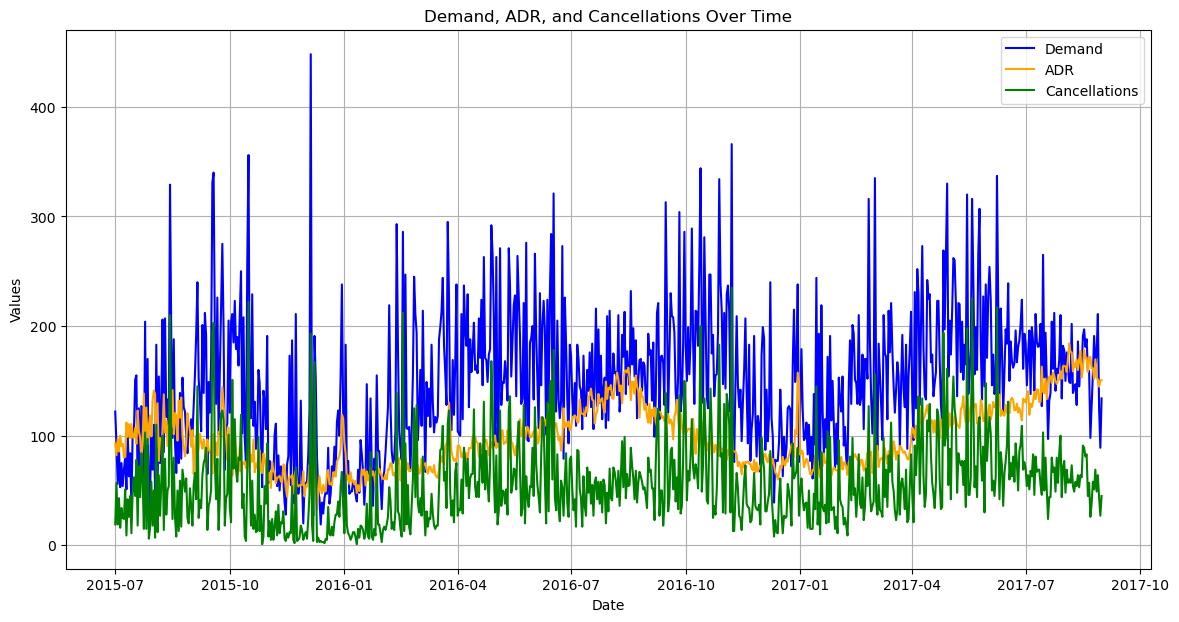

In [37]:
daily_demand = df.groupby('arrival_date').size()
daily_adr = df.groupby('arrival_date')['adr'].mean()
daily_cancellations = df.groupby('arrival_date')['is_canceled'].sum()

plt.figure(figsize=(14,7))
plt.plot(daily_demand.index, daily_demand.values, label='Demand', color='blue')
plt.plot(daily_adr.index, daily_adr.values, label='ADR', color='orange')
plt.plot(daily_cancellations.index, daily_cancellations.values, label='Cancellations', color='green')

plt.title("Demand, ADR, and Cancellations Over Time")
plt.xlabel("Date")
plt.ylabel("Values")
plt.legend()
plt.grid(True)
plt.show()
